# De Bruijn Graphs for pseudoalignment
Pseudoalignment using de Bruijn graphs allows for fast assignment of reads to different reference sequences. The [_kallisto_](https://www.nature.com/articles/nbt.3519) algorithm for transcript quantification introduced this idea. 

Go through the following steps either by hand or using code. 

1. Consider the three reference transcript sequences $T_1$ = GCAATCGACT, $T_2$ = GCAAGCGACT, and $T_3$ = TAAGCAGG. For each sequence, list all $k$-mers for $k=3$, and construct the transcript de Bruijn graph (T-DBG): 
    - use unique 3-mers as nodes, do not merge reverse complements
    - draw directed edges between nodes that occur consecutively in any transcript
    - indicate, e.g. using different colours, which transcript sequence(s) each node of the T-DBG is compatible with
    
> The $k$-compatibility class of a $k$-mer is the set of transcripts that contain it. In a coloured de Bruijn graph, this is the set of colours associated with each node. 

2. Determine the 3-compatibility classes that exist in your graph, and assign each 3-mer to its corresponding class. Bonus: One class that could exist does not, which is it? 

3. Now consider the three reads $r_1$ = AATCGAC, $r_2$ = TAAGCA, and $r_3$ = AAGC. For each read: 
    - match all 3-mers of the read with nodes of the T-DBG and note the corresponding compatibility class
    - determine the read's 3-compatibility class by taking the intersection of the compatibility classes of all its 3-mers
    - which transcripts could the reads originate from? How many reads would you assign to each transcript?

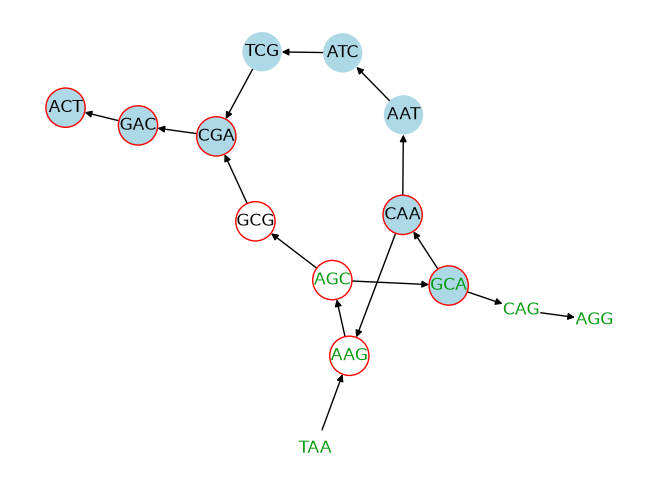

In [67]:
import networkx as nx
import matplotlib.pyplot as plt


t1 = "GCAATCGACT"
t2 = "GCAAGCGACT"
t3 = "TAAGCAGG"

node_set = set()
for seq in [t1, t2, t3]:
    node_set.update([seq[i:i+3] for i in range(0, len(seq) - 2)])
nodes = [s for s in node_set]
edges = []
for seq in [t1, t2, t3]:
    for i in range(0, len(seq) - 3):
        i_prev = nodes.index(seq[i:i+3])
        i_next = nodes.index(seq[i+1:i+4])
        edges.append((i_prev, i_next))

t1_nodes = [seq for seq in nodes if seq in t1]
t2_nodes = [seq for seq in nodes if seq in t2]
t3_nodes = [seq for seq in nodes if seq in t3]

G = nx.DiGraph()
G.add_edges_from((nodes[a], nodes[b]) for a, b in edges)
node_colors = ["lightblue" if n in t1_nodes else "none" for n in G.nodes]
edge_colors = ["red" if n in t2_nodes else "none" for n in G.nodes]

pos = nx.kamada_kawai_layout(G)
nx.draw(G, pos, node_color=node_colors, edgecolors=edge_colors, node_size=800)

for n in nodes:
    font_color = "#009A0A" if n in t3 else "#000000"
    nx.draw_networkx_labels(G, pos, labels={n: n}, font_color=font_color)

plt.show()

2. Determine the 3-compatibility classes that exist in your graph, and assign each 3-mer to its corresponding class. Bonus: One class that could exist does not, which is it? 


In [72]:
from pprint import pprint

classes = {n: [] for n in nodes}
for seq, name in zip([t1_nodes, t2_nodes, t3_nodes], ["T1", "T2", "T3"]):
    for s in seq:
        classes[s].append(name)
pprint(classes)

# Missing: T3, T1

{'AAG': ['T2', 'T3'],
 'AAT': ['T1'],
 'ACT': ['T1', 'T2'],
 'AGC': ['T2', 'T3'],
 'AGG': ['T3'],
 'ATC': ['T1'],
 'CAA': ['T1', 'T2'],
 'CAG': ['T3'],
 'CGA': ['T1', 'T2'],
 'GAC': ['T1', 'T2'],
 'GCA': ['T1', 'T2', 'T3'],
 'GCG': ['T2'],
 'TAA': ['T3'],
 'TCG': ['T1']}


3. Now consider the three reads $r_1$ = AATCGAC, $r_2$ = TAAGCA, and $r_3$ = AAGC. For each read: 
    - match all 3-mers of the read with nodes of the T-DBG and note the corresponding compatibility class
    - determine the read's 3-compatibility class by taking the intersection of the compatibility classes of all its 3-mers
    - which transcripts could the reads originate from? How many reads would you assign to each transcript?

In [81]:
r1 = "AATCGAC"
r2 = "TAAGCA"
r3 = "AAGC"

for seq in [r1, r2, r3]:
    print(f"Sequence {seq}:")
    counts = {"T1": 0, "T2": 0, "T3": 0}
    total_3_mers = 0
    for i in range(len(seq) - 2):
        c = classes[seq[i:i+3]]
        print(f"  {seq[i:i+3]}: {c}")
        for x in c:
            counts[x] += 1
        total_3_mers += 1
    print(f"Best Fits: {[name for name, count in counts.items() if count == total_3_mers]}")
    print()

Sequence AATCGAC:
  AAT: ['T1']
  ATC: ['T1']
  TCG: ['T1']
  CGA: ['T1', 'T2']
  GAC: ['T1', 'T2']
Best Fits: ['T1']

Sequence TAAGCA:
  TAA: ['T3']
  AAG: ['T2', 'T3']
  AGC: ['T2', 'T3']
  GCA: ['T1', 'T2', 'T3']
Best Fits: ['T3']

Sequence AAGC:
  AAG: ['T2', 'T3']
  AGC: ['T2', 'T3']
Best Fits: ['T2', 'T3']

